# Tutorial 8: Zero-copy GPU arrays

When the data is already on the GPU (a beamformer writes it there, or a
PyTorch / CuPy / Numba pipeline produced it), dmtlib's engines can read and
write it in place. No copy to the host and back, no copy on the device, and
the call returns at once with the work queued on a CUDA stream.

This tutorial measures what that buys, then builds a small search that never
leaves the GPU, shows the same calls from CuPy and Numba, and streams blocks
through one output buffer.

:::{note}
This notebook needs a CUDA GPU, a CUDA build of dmtlib, PyTorch with CUDA,
CuPy and Numba. The documentation shows the outputs of a run on the machine
printed below; it is not re-executed when the docs are built.
:::

In [1]:
import subprocess
import time
import warnings
from pathlib import Path

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import torch

with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    from numba import cuda as nb_cuda

import dmtlib
from dmtlib import FDMT, DDMTPlan
from dmtlib.simulate import DM_CONSTANT

plt.rcParams["figure.dpi"] = 80


def dmt_version() -> str:
    try:
        return subprocess.run(
            ["git", "describe", "--always", "--dirty"],
            cwd=Path(dmtlib.__file__).resolve().parent,
            capture_output=True,
            text=True,
            check=True,
        ).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return dmtlib.__version__


def cuda_version(v: int) -> str:
    return f"{v // 1000}.{v % 1000 // 10}"


try:
    import numba_cuda

    numba_version = f"numba-cuda {numba_cuda.__version__}"
except ImportError:
    import numba

    numba_version = f"numba {numba.__version__} (built-in numba.cuda)"

print(f"GPU:          {torch.cuda.get_device_name()}")
print(f"CUDA driver:  {cuda_version(cp.cuda.runtime.driverGetVersion())}")
print(f"dmt:          {dmt_version()} (backends {dmtlib.available_backends()})")
print(f"PyTorch:      {torch.__version__} (CUDA {torch.version.cuda})")
print(f"CuPy:         {cp.__version__} (CUDA {cuda_version(cp.cuda.runtime.runtimeGetVersion())})")
print(f"Numba:        {numba_version}")

GPU:          NVIDIA L40
CUDA driver:  12.6
dmt:          01e1d38-dirty (backends ['cpu', 'cuda'])
PyTorch:      2.14.1+cu126 (CUDA 12.6)
CuPy:         14.2.0 (CUDA 12.9)
Numba:        numba-cuda 0.30.4


## The cost of the host round trip

We take an L-band setup from the benchmark suite (`cryopaf_lband` in
`bench/scripts/plot_suite.py`): 1152 channels between 1100 and 1714 MHz,
455.6 µs samples, blocks of 32768 samples (15 s), and the suite's
Levin-spaced DM grid up to 2000 pc cm⁻³.

The same `FDMT` type runs on the GPU in both cases below:

- **NumPy in, NumPy out.** `execute()` copies the waterfall to the GPU,
  transforms it and copies the DM–time plane back. It blocks until the
  result is on the host. The output buffer is preallocated (`out=`) so the
  timing does not include allocating it.
- **Device in, device out.** The waterfall is a `torch.cuda` tensor and the
  output a preallocated tensor. Only the transform runs. We time it with CUDA
  events on the stream, and separately time how long the Python call itself
  takes to return.

In [2]:
f_min, f_max, nchans, tsamp = 1100.0, 1714.0, 1152, 455.6e-6
nsamps = 32768
dm_grid = np.asarray(
    DDMTPlan.generate_levin_dm_grid_piecewise(
        0.0, 2000.0, tsamp, tsamp, f_min, f_max, nchans, 1.1
    )
)
fdmt = FDMT(f_min, f_max, nchans, nsamps, tsamp, dm_grid=dm_grid, backend="cuda")
plan = fdmt.plan
in_mb = nchans * nsamps * 4 / 1e6
out_mb = plan.dmt_size * 4 / 1e6
print(f"{plan.dmt_ndms} DM trials, dt_max = {plan.dt_max} samples")
print(f"input  ({nchans}, {nsamps}) float32: {in_mb:.0f} MB")
print(f"output ({plan.dmt_ndms}, {plan.dmt_nsamps}) float32: {out_mb:.0f} MB")

1941 DM trials, dt_max = 8877 samples
input  (1152, 32768) float32: 151 MB
output (1941, 32768) float32: 254 MB


In [3]:
rng = np.random.default_rng(0)
wf_host = rng.standard_normal((nchans, nsamps), dtype=np.float32)
out_host = np.empty(plan.dmt_size, dtype=np.float32)
wf_dev = torch.from_numpy(wf_host).cuda()
out_dev = torch.empty(plan.dmt_size, device="cuda")
nwarm, nrep = 3, 10

# NumPy in, NumPy out (blocking).
for _ in range(nwarm):
    fdmt.execute(wf_host, out=out_host)
host_ms = []
for _ in range(nrep):
    t0 = time.perf_counter()
    fdmt.execute(wf_host, out=out_host)
    host_ms.append(1e3 * (time.perf_counter() - t0))

# Device in, device out (asynchronous on the current stream).
for _ in range(nwarm):
    fdmt.execute(wf_dev, out=out_dev)
torch.cuda.synchronize()
start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
dev_ms, call_ms = [], []
for _ in range(nrep):
    start.record()
    t0 = time.perf_counter()
    fdmt.execute(wf_dev, out=out_dev)
    call_ms.append(1e3 * (time.perf_counter() - t0))
    end.record()
    end.synchronize()
    dev_ms.append(start.elapsed_time(end))

# For scale: the two copies alone, done by PyTorch (pageable host memory).
for _ in range(nwarm):
    wf_dev.copy_(torch.from_numpy(wf_host))
    torch.from_numpy(out_host).copy_(out_dev)
copy_ms = []
for _ in range(nrep):
    t0 = time.perf_counter()
    wf_dev.copy_(torch.from_numpy(wf_host))
    torch.from_numpy(out_host).copy_(out_dev)
    torch.cuda.synchronize()
    copy_ms.append(1e3 * (time.perf_counter() - t0))

med = {k: float(np.median(v)) for k, v in
       {"host": host_ms, "device": dev_ms, "call": call_ms, "copies": copy_ms}.items()}
print(f"NumPy in/out (H2D + FDMT + D2H): {med['host']:7.1f} ms per block")
print(f"device in/out (FDMT only):       {med['device']:7.1f} ms per block")
print(f"  execute() returns after:       {med['call']:7.3f} ms")
print(f"H2D + D2H copies alone:          {med['copies']:7.1f} ms")
print(f"block duration:                  {1e3 * nsamps * tsamp:7.1f} ms of data")
print(f"speed-up of the device path:     {med['host'] / med['device']:.1f}x")

NumPy in/out (H2D + FDMT + D2H):    34.5 ms per block
device in/out (FDMT only):          16.0 ms per block
  execute() returns after:         0.641 ms
H2D + D2H copies alone:             18.0 ms
block duration:                  14929.1 ms of data
speed-up of the device path:     2.2x


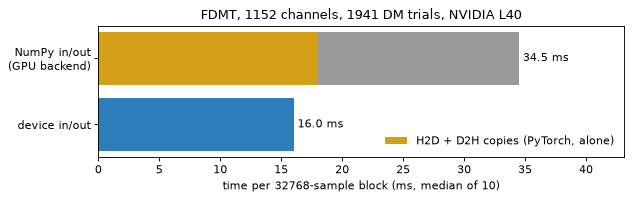

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.6))
labels = ["NumPy in/out\n(GPU backend)", "device in/out"]
ax.barh(labels, [med["host"], med["device"]], color=["#9a9a9a", "#2f7ebc"])
ax.barh(labels[:1], [med["copies"]], color="#d4a017", label="H2D + D2H copies (PyTorch, alone)")
for y, v in enumerate([med["host"], med["device"]]):
    ax.text(v, y, f" {v:.1f} ms", va="center")
ax.set_xlabel("time per 32768-sample block (ms, median of 10)")
ax.set_xlim(0, med["host"] * 1.25)
ax.invert_yaxis()
ax.legend(loc="lower right", frameon=False)
ax.set_title(f"FDMT, {nchans} channels, {plan.dmt_ndms} DM trials, {torch.cuda.get_device_name()}")
fig.tight_layout()
plt.show()

In the run above, the NumPy path takes 34.5 ms per block and the device path
16.0 ms: the transform is the same, and the difference is the two copies
(18.0 ms when PyTorch does them alone). Keeping the data on the GPU makes
each block about twice as fast here. The `execute()` call itself returns
after about 0.6 ms, the time to queue the kernels, so the CPU is free while
the GPU works. (Across repeated runs on this machine the NumPy path varied
between about 32 and 35 ms, the device path not at all: pageable host
copies are the noisy part.)

Both are far faster than real time for one beam (a block is 15 s of data).
The copies matter when the GPU is shared by many beams, and they are pure
overhead when the data comes from, or goes on to, other GPU code.

## A search that stays on the GPU (PyTorch)

Next, a complete toy search in PyTorch: simulate a waterfall with a dispersed
pulse on the GPU, dedisperse it, convert to S/N, run a boxcar search, and
keep the best candidates. Only the candidate list (and, for the figure, a
crop of the DM–time plane) is copied to the host.

The noise is unit-variance white noise per channel, so
`fdmt.get_effective_sigma_grid(w)` gives the noise of a width-`w` boxcar on
each DM trial. The first `startup_samples` outputs of a fresh `mode="valid"`
engine are partial sums and are skipped.

In [5]:
def simulate_on_gpu(dm: float, t0: int, width: int, amp: float, seed: int) -> torch.Tensor:
    # Gaussian noise plus a top-hat pulse of `width` samples, delayed in each
    # channel (centre frequency) relative to the top of the band.
    gen = torch.Generator(device="cuda").manual_seed(seed)
    x = torch.randn((nchans, nsamps), device="cuda", generator=gen)
    df = (f_max - f_min) / nchans
    f_chan = f_min + df * (torch.arange(nchans, device="cuda", dtype=torch.float64) + 0.5)
    delay = DM_CONSTANT * dm * (f_chan**-2 - f_max**-2) / tsamp
    start = (t0 + delay).round().long()
    rows = torch.arange(nchans, device="cuda")
    for k in range(width):
        x[rows, start + k] += amp
    return x


dm_true, t0_true, width_true = 812.0, 20000, 4
x = simulate_on_gpu(dm_true, t0_true, width_true, amp=0.35, seed=1)

fdmt.reset_history()
dmt = fdmt.execute(x)  # a torch.Tensor on the GPU, (ndm, nsamps)
print(type(dmt).__name__, tuple(dmt.shape), dmt.dtype, dmt.device)

Tensor (1941, 32768) torch.float32 cuda:0


In [6]:
widths = [1, 2, 4, 8, 16, 32]
skip = fdmt.startup_samples
dms = torch.from_numpy(np.asarray(fdmt.dm_grid_final)).cuda()

best_snr = torch.full_like(dmt[:, skip:], -torch.inf)
best_width = torch.zeros_like(best_snr, dtype=torch.int32)
csum = torch.cumsum(dmt[:, skip:], dim=1)
for w in widths:
    sigma = torch.from_numpy(fdmt.get_effective_sigma_grid(w)).cuda()[:, None]
    box = torch.nn.functional.pad(csum[:, w:] - csum[:, :-w], (w, 0), value=-torch.inf)
    snr = box / sigma
    better = snr > best_snr
    best_snr = torch.where(better, snr, best_snr)
    best_width = torch.where(better, w, best_width)

# Candidates: the 5 strongest local maxima in the S/N plane (3 x 65 cells).
peaks = best_snr == torch.nn.functional.max_pool2d(
    best_snr[None, None], (3, 65), stride=1, padding=(1, 32)
)[0, 0]
snr_at_peaks = torch.where(peaks, best_snr, -torch.inf)
top = torch.topk(snr_at_peaks.flatten(), 5)
rows, cols = top.indices // best_snr.shape[1], top.indices % best_snr.shape[1]
cands = torch.stack(
    [dms[rows].float(), (cols + skip).float(), best_width[rows, cols].float(), top.values]
).T.cpu().numpy()  # the first device -> host copy: 5 rows

print(f"injected: DM {dm_true}, width {width_true} samples")
print("   DM       sample  width   S/N")
for dm_c, t_c, w_c, s_c in cands:
    print(f"{dm_c:8.1f} {int(t_c):10d} {int(w_c):5d} {s_c:7.1f}")

injected: DM 812.0, width 4 samples
   DM       sample  width   S/N
   812.1      23598     4    21.1
   123.3      15706     4     5.8
   433.0      14665     1     5.5
   249.8      18239     4     5.5
   684.9      32613     1     5.4


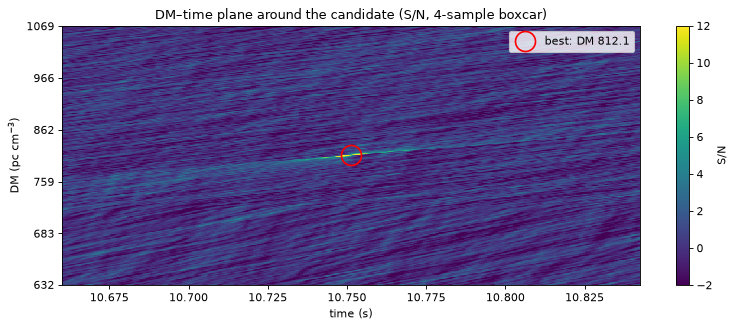

In [7]:
# S/N of the best candidate's boxcar width around it; only this crop is
# copied to the host, for the figure.
row, col, w = int(rows[0]), int(cols[0]) + skip, int(cands[0, 2])
lo, hi = col - 200, col + 200  # samples
r0, r1 = max(row - 200, 0), min(row + 200, plan.dmt_ndms)  # DM trials
cs = torch.cumsum(dmt[r0:r1, lo - w : hi], dim=1)
sigma_w = torch.from_numpy(fdmt.get_effective_sigma_grid(w)[r0:r1]).cuda()[:, None]
crop = ((cs[:, w:] - cs[:, :-w]) / sigma_w).cpu().numpy()

dm_axis = np.asarray(fdmt.dm_grid_final)
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(
    crop, aspect="auto", origin="lower", cmap="viridis", interpolation="nearest",
    extent=[lo * tsamp, hi * tsamp, r0, r1], vmin=-2, vmax=12,
)
ticks = np.linspace(r0, r1 - 1, 6).astype(int)
ax.set_yticks(ticks + 0.5, [f"{dm_axis[t]:.0f}" for t in ticks])
ax.plot(col * tsamp, row + 0.5, "o", mfc="none", mec="r", ms=18, mew=1.5, label=f"best: DM {dm_axis[row]:.1f}")
ax.set_xlabel("time (s)")
ax.set_ylabel("DM (pc cm$^{-3}$)")
ax.set_title(f"DM–time plane around the candidate (S/N, {w}-sample boxcar)")
ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, label="S/N")
fig.tight_layout()
plt.show()

The injected pulse is the top candidate: DM 812.1 (the trial nearest to
812), the injected width of 4 samples, S/N 21.1. The other four are noise
peaks at S/N 5.4–5.8. FDMT output times refer to the bottom of the band
(`f_min`), so the candidate sits about 3600 samples (the DM-812 sweep across
the band) after the top-of-band arrival time used in the simulation.

The only copies to the host were the five-row candidate table and the crop
for the figure; the 151 MB waterfall, the 254 MB DM–time plane and the S/N
planes stayed on the GPU.

## The same with CuPy and Numba

Any library that exports DLPack (`__dlpack__`) or the CUDA array interface
(`__cuda_array_interface__`) works the same way, and the result comes back as
an array of the input's library. Below, the waterfall from the PyTorch
section is shared with CuPy and Numba without copying it (all three views
have the same device pointer), and each transform matches PyTorch's.

In [8]:
x_cp = cp.from_dlpack(x)                 # same memory as the torch tensor
x_nb = nb_cuda.as_cuda_array(x_cp)       # same memory again (CUDA array interface)
print("same pointer:", x.data_ptr() == x_cp.data.ptr == x_nb.__cuda_array_interface__["data"][0])

results = {}
for name, arr in [("torch", x), ("cupy", x_cp), ("numba", x_nb)]:
    fdmt.reset_history()
    results[name] = fdmt.execute(arr)
    print(f"{name:6s} -> {type(results[name]).__module__}.{type(results[name]).__name__}")
torch.cuda.synchronize()
nb_cuda.synchronize()

ref = cp.from_dlpack(results["torch"])
for name in ("cupy", "numba"):
    diff = float(cp.abs(cp.asarray(results[name]) - ref).max())
    print(f"max |{name} - torch| = {diff}")

same pointer: True
torch  -> torch.Tensor
cupy   -> cupy.ndarray
numba  -> numba.cuda.cudadrv.devicearray.DeviceNDArray
max |cupy - torch| = 0.0
max |numba - torch| = 0.0


Numba arrays only implement the CUDA array interface (checked with
numba-cuda 0.30), so dmtlib reads their pointer, shape and type directly. A
Numba array bound to a stream reports that stream, and the engine queues an
event wait on it before the transform (set
`NUMBA_CUDA_ARRAY_INTERFACE_SYNC=0` to skip that, as in Numba). A Numba
result is allocated on the call's stream and bound to it.

## Streaming blocks through one buffer

A real-time search sees one block after another. In `mode="valid"` the engine
carries the overlap-save history between calls (see
[Tutorial 6](06_realtime_streaming_and_batching.ipynb)), so the outputs of
consecutive blocks are the transform of the whole stream. On the GPU, one
preallocated `out=` buffer can serve every block if each block's output is
consumed on the same stream before the next call overwrites it.

Here eight blocks of 16384 samples go through a dedicated stream. Each output
is copied into a slice of a big buffer (standing in for whatever the search
does with it), and the result is compared with one transform of the whole
stream.

In [9]:
nblock, nblocks = 16384, 8
stream_fdmt = FDMT(f_min, f_max, nchans, nblock, tsamp, dm_grid=dm_grid, backend="cuda")
whole_fdmt = FDMT(f_min, f_max, nchans, nblock * nblocks, tsamp, dm_grid=dm_grid, backend="cuda")
ndm = stream_fdmt.plan.dmt_ndms

gen = torch.Generator(device="cuda").manual_seed(2)
data = torch.randn((nchans, nblock * nblocks), device="cuda", generator=gen)
blocks = [data[:, i * nblock : (i + 1) * nblock].contiguous() for i in range(nblocks)]

s = torch.cuda.Stream()
out = torch.empty((ndm, nblock), device="cuda")
streamed = torch.empty((ndm, nblock * nblocks), device="cuda")
torch.cuda.synchronize()
with torch.cuda.stream(s):
    for i, block in enumerate(blocks):
        stream_fdmt.execute(block, out=out)            # queued on s
        streamed[:, i * nblock : (i + 1) * nblock] = out  # consumed on s
s.synchronize()

whole = whole_fdmt.execute(data)
torch.cuda.synchronize()
err = (streamed - whole).abs().max().item()
print(f"max |streamed - one-shot| = {err:.2e}  (max |one-shot| = {whole.abs().max().item():.1f})")

max |streamed - one-shot| = 0.00e+00  (max |one-shot| = 185.0)


### Overlapping upload and compute

When the blocks arrive in host memory, the upload of block *i+1* can run
while block *i* is transformed: copy on one stream into a double buffer,
compute on another, with events in both directions (the compute stream waits
for the upload; the upload into a buffer waits until the transform that read
it has finished). The host buffers are pinned so the copies are asynchronous.

In [10]:
host_blocks = [b.cpu().pin_memory() for b in blocks]
dev_buf = [torch.empty((nchans, nblock), device="cuda") for _ in range(2)]
copy_s, comp_s = torch.cuda.Stream(), torch.cuda.Stream()
best = torch.empty((nblocks, ndm), device="cuda")


def run(overlap: bool) -> float:
    stream_fdmt.reset_history()
    uploaded = [torch.cuda.Event() for _ in range(2)]
    consumed = [torch.cuda.Event() for _ in range(2)]
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for i, hb in enumerate(host_blocks):
        k = i % 2 if overlap else 0
        up = copy_s if overlap else comp_s
        with torch.cuda.stream(up):
            if i >= 2 and overlap:
                up.wait_event(consumed[k])
            dev_buf[k].copy_(hb, non_blocking=True)
            uploaded[k].record(up)
        with torch.cuda.stream(comp_s):
            comp_s.wait_event(uploaded[k])
            stream_fdmt.execute(dev_buf[k], out=out)
            best[i] = out.amax(dim=1)  # e.g. the peak of each DM trial
            consumed[k].record(comp_s)
    comp_s.synchronize()
    return 1e3 * (time.perf_counter() - t0)


for _ in range(2):
    run(False), run(True)
serial = float(np.median([run(False) for _ in range(5)]))
overlapped = float(np.median([run(True) for _ in range(5)]))
print(f"{nblocks} blocks, upload then compute on one stream: {serial:6.1f} ms")
print(f"{nblocks} blocks, upload and compute overlapped:     {overlapped:6.1f} ms")
print(f"data duration: {1e3 * nblocks * nblock * tsamp:.0f} ms")

8 blocks, upload then compute on one stream:   84.3 ms
8 blocks, upload and compute overlapped:       67.8 ms
data duration: 59716 ms


Overlapping the uploads with the transforms brings the eight blocks from
84.3 ms to 67.8 ms in the run above. The output of each block was consumed
on the compute stream (`best[i] = out.amax(...)`) before the next
`execute()` reused `out`; both are queued on the same stream, so no
synchronization is needed.

## Rules of the road

- **Nothing is converted.** Device arrays must be C-contiguous with the exact
  dtype (float32; packed uint8 with `nbits`; int8/uint8 baseband for
  `CohFDMT`). Anything else raises `TypeError`, because a silent conversion
  would be a hidden copy.
- **Calls are asynchronous on `stream`.** `stream=None` means the input
  library's current stream (`torch.cuda.current_stream()`, CuPy's current
  stream; Numba's default stream). Synchronize that stream, or keep working
  on it, before reading the result on the host.
- **Producers are ordered before the call.** DLPack inputs are exported with
  `__dlpack__(stream=...)`. PyTorch orders the work on its *current* stream
  at the time of the call, so call inside `with torch.cuda.stream(...)` of
  the stream that wrote the input, or synchronize that stream first. CUDA
  array interface inputs that state a `stream` get an event wait.
- **Keep inputs alive until the stream has consumed them.** PyTorch inputs
  are marked in use on the call's stream (`Tensor.record_stream`), so
  dropping them right after the call is safe. For CuPy, Numba and other
  libraries, keep a reference (or synchronize) when the input was allocated
  on a different stream than the call's.
- **`out=` for other libraries.** Without `out=`, results are allocated by
  PyTorch, CuPy or Numba on the call's stream. Other producers (JAX, or a
  bare `__cuda_array_interface__` object) must pass a writeable `out=`; the
  result is then a view of it.
- **Warm up before timing.** With CUDA's lazy module loading (the default
  in CUDA 12), the first launch of each kernel in a process loads its module,
  which takes milliseconds and synchronizes the device.